# Lab 5A — Find the fault: temporal convolution and pooling
### Beginner MSc laboratory • Lecture 5, slides 1–98 • approximately 120 minutes

**Practical question:** A sensor captures a short vibration window. Can we detect whether it contains **high-frequency ringing** or only a **smooth low-frequency disturbance**, even when the event occurs at an unpredictable time?

By the end, you should be able to explain a Conv1D filter and its feature map, predict convolution and pooling output shapes, interpret local/global pooling, train a small CNN and evaluate it on *unseen* data.

**Preparation:** Only basic Python and the earlier RNN labs are assumed. All data are generated locally; no file download or GPU is required. Each cell includes comments. Run in order. Tasks marked **Try it** invite you to change small pieces of working code.

**We deliberately stop at slide 98:** We introduce the intuitive notion of receptive field, but **do not yet use causal convolutions, dilations, TCNs or WaveNet**.

## 0. Environment and reproducibility — 5 min

The previous RNN lab used Keras. We continue with Keras, but explicitly choose the **PyTorch backend** (which runs on a CPU). This makes it possible to run without TensorFlow.

If the imports fail, install: `pip install "keras>=3" torch numpy matplotlib scikit-learn ipykernel` and restart the kernel.

In [1]:
import os
# This MUST be set before importing Keras.
os.environ["KERAS_BACKEND"] = "torch"
os.environ["OMP_NUM_THREADS"] = "2"  # keep CPU experiments lightweight

import numpy as np
import matplotlib.pyplot as plt
import keras
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 21
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=3, suppress=True)
print("Keras:", keras.__version__, "| backend:", keras.backend.backend())

Keras: 3.13.2 | backend: torch


## 1. A Conv1D filter is a small, reusable pattern detector — 15 min

From lecture slides 21–23, consider the **single-channel** sequence `x = [2, 3, 5, 4, 1]` and filter `w = [-1, 0, 1]`.

The first filter response is `-1×2 + 0×3 + 1×5 = 3`. Moving the *same* weights one position gives another response. In deep-learning libraries, this operation is technically *cross-correlation* (the weights are not reversed), though it is called convolution.

**Try it:** Predict all three responses by hand. Then run the cell. What happens when we apply ReLU?

In [2]:
# A tiny numerical example; no neural-network training is involved.
x = np.array([2., 3., 5., 4., 1.])
w = np.array([-1., 0., 1.])

# Manually slide the filter across every complete region of length 3.
hand_computed = []
for start in range(len(x) - len(w) + 1):
    region = x[start:start + len(w)]
    response = np.sum(region * w)  # element-wise products, then sum
    hand_computed.append(response)
    print(f"position {start+1}: region={region} -> response={response:.1f}")

# A NumPy function performs the same cross-correlation calculation.
feature_map = np.correlate(x, w, mode="valid")
relu_map = np.maximum(feature_map, 0)
print("Raw feature map:", feature_map)
print("After ReLU:    ", relu_map)
assert np.allclose(feature_map, hand_computed)

position 1: region=[2. 3. 5.] -> response=3.0
position 2: region=[3. 5. 4.] -> response=1.0
position 3: region=[5. 4. 1.] -> response=-4.0
Raw feature map: [ 3.  1. -4.]
After ReLU:     [3. 1. 0.]


**Think:** If the same rise appears 30 samples later, do we need a new set of filter weights to detect it? What does a large filter response tell us?

> **INSTRUCTOR NOTES — After Exercise 1**
>
> **Expected:** the three responses are `[3, 1, -4]` and ReLU produces `[3, 1, 0]`. Weight sharing means that the same local pattern is detectable at different time positions, without learning a separate filter for each one.

## 2. Kernel size, padding, stride and tensor shapes — 15 min

For **Keras** Conv1D, input has shape **[N, L, d]**: windows × time steps × channels. If a layer has F filters, its output has F channels. For `padding='valid'`, effective kernel K, stride S, dilation 1:

`L_out = floor((L - K)/S) + 1`

For `padding='same'`, stride 1 preserves L; stride 2 gives approximately half the temporal positions.

**Try it:** Before running, predict the output shapes for all cases. Change `KERNEL` or `STRIDE` and check whether your prediction is correct.

In [3]:
# Eight 128-step windows, each containing one vibration channel.
dummy = np.zeros((8, 128, 1), dtype="float32")

configs = [
    {"kernel_size": 5, "strides": 1, "padding": "valid"},
    {"kernel_size": 5, "strides": 1, "padding": "same"},
    {"kernel_size": 5, "strides": 2, "padding": "valid"},
    {"kernel_size": 5, "strides": 2, "padding": "same"},
]

for cfg in configs:
    # Four filters => four output feature maps, regardless of the input channel count.
    layer = keras.layers.Conv1D(filters=4, **cfg)
    output = layer(dummy)
    print(f"{cfg} -> input {dummy.shape} -> output {tuple(output.shape)}")

# For one Conv1D layer: weights = K*d*F, biases = F.
print("Example parameter count (K=5,d=1,F=4):", 5 * 1 * 4 + 4)

{'kernel_size': 5, 'strides': 1, 'padding': 'valid'} -> input (8, 128, 1) -> output (8, 124, 4)
{'kernel_size': 5, 'strides': 1, 'padding': 'same'} -> input (8, 128, 1) -> output (8, 128, 4)
{'kernel_size': 5, 'strides': 2, 'padding': 'valid'} -> input (8, 128, 1) -> output (8, 62, 4)
{'kernel_size': 5, 'strides': 2, 'padding': 'same'} -> input (8, 128, 1) -> output (8, 64, 4)
Example parameter count (K=5,d=1,F=4): 24


> **INSTRUCTOR NOTES — After Exercise 2**
>
> **Expected shapes:** valid/stride1 `[8,124,4]`; same/stride1 `[8,128,4]`; valid/stride2 `[8,62,4]`; same/stride2 `[8,64,4]`. Trainable parameters: `5×1×4 + 4 = 24`. Number of filters sets output channels; the temporal dimension depends on kernel, padding and stride.

## 3. Local and global pooling — 15 min

Pooling summarizes a feature map, rather than learning another set of filter weights. **Max** pooling emphasizes the strongest activation; **average** pooling emphasizes overall activity. **Global** pooling collapses the *entire temporal axis* to one value per feature map.

**Try it:** Compute the three pairwise maximums and averages manually. Then compare two signals whose peaks occur at different times: can global max pooling report *where* the peak occurred?

In [4]:
# One feature map: shape [batch=1, time=6, channels=1].
activations = np.array([0.2, 0.4, 2.8, 2.5, 0.3, 0.1], dtype="float32")
a = activations[None, :, None]

local_max = keras.layers.MaxPooling1D(pool_size=2, strides=2)(a)
local_avg = keras.layers.AveragePooling1D(pool_size=2, strides=2)(a)
global_max = keras.layers.GlobalMaxPooling1D()(a)
global_avg = keras.layers.GlobalAveragePooling1D()(a)

print("Local max: ", np.asarray(local_max).flatten())
print("Local mean:", np.asarray(local_avg).flatten())
print("Global max:", np.asarray(global_max).flatten())
print("Global mean:", np.asarray(global_avg).flatten())

# The same large activation at a different time position.
shift_a = np.zeros((1, 16, 1), dtype="float32")
shift_b = np.zeros((1, 16, 1), dtype="float32")
shift_a[0, 3, 0] = 5
shift_b[0, 12, 0] = 5
G = keras.layers.GlobalMaxPooling1D()
print("Peak at t=3:", np.asarray(G(shift_a)).ravel())
print("Peak at t=12:", np.asarray(G(shift_b)).ravel())

Local max:  [0.4 2.8 0.3]
Local mean: [0.3  2.65 0.2 ]
Global max: [2.8]
Global mean: [1.05]
Peak at t=3: [5.]
Peak at t=12: [5.]


> **INSTRUCTOR NOTES — After Exercise 3**
>
> **Expected:** max pooling gives `[0.4,2.8,0.3]`, average pooling `[0.3,2.65,0.2]`. Global max and average yield one number for the feature map: `2.8` and approximately `1.05`. Both shifted impulses have global max `5`; absolute event time is lost.

## 4. The engineering challenge: detect ringing anywhere — 15 min

We generate independent 128-sample windows, sampled at 100 Hz:

- **Class 0 — smooth event:** a short, low-frequency disturbance superimposed on noisy vibration.
- **Class 1 — ringing event:** a localized, faster oscillation superimposed on the *same type* of background.

Every event has a random position and amplitude. The two event motifs have approximately matched energy; the model should learn the *local temporal shape*, not a particular event location.

We split **independently generated recordings** into training, validation and test sets. We never use test data to choose model settings.

Training: (900, 128, 1) (900,)
Validation: (200, 128, 1) (200,)
Test: (200, 128, 1) (200,)


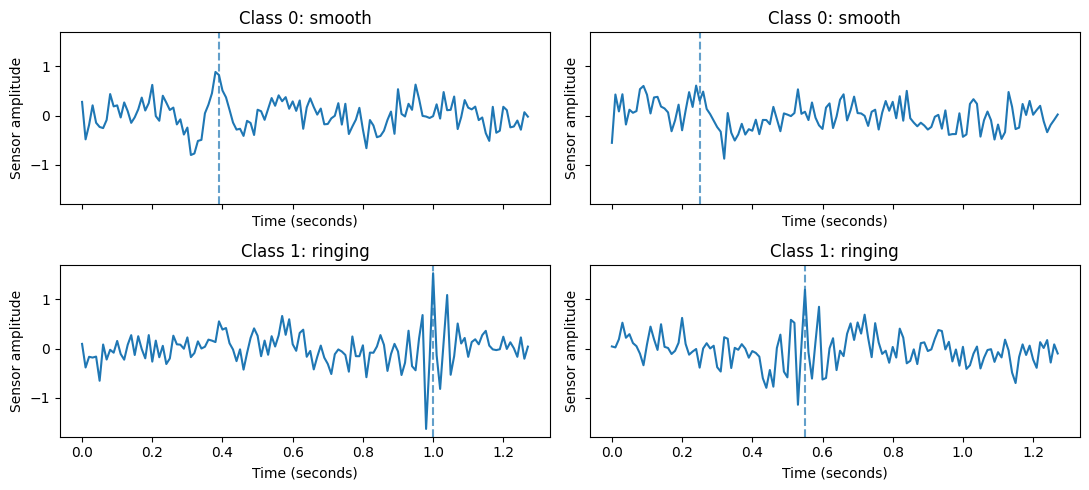

In [5]:
FS = 100        # sampling frequency, samples per second
L = 128         # samples in each window


def make_sensor_windows(count, seed):
    """Generate independent labeled sensor windows; no downloads needed."""
    rng = np.random.default_rng(seed)
    # Balanced classes, randomly shuffled so order is not related to labels.
    y = np.array([0, 1] * (count // 2), dtype=np.int64)
    rng.shuffle(y)
    X = np.empty((count, L, 1), dtype="float32")
    event_centres = np.empty(count, dtype=int)
    t = np.arange(L) / FS
    q = np.arange(-12, 13)  # local event: 25 samples
    envelope = np.exp(-0.5 * (q / 5.0) ** 2)

    for i, label in enumerate(y):
        # Background noise + two benign low-frequency vibration components.
        signal = (
            0.23 * rng.normal(size=L)
            + 0.14 * np.sin(2*np.pi*rng.uniform(1.0, 2.5)*t + rng.uniform(0, 2*np.pi))
            + 0.07 * np.sin(2*np.pi*rng.uniform(4.0, 6.0)*t + rng.uniform(0, 2*np.pi))
        )
        centre = int(rng.integers(16, L - 16))
        # A relatively smooth event versus a rapidly oscillating ring-down.
        cycles_per_sample = 0.055 if label == 0 else 0.27
        motif = envelope * np.cos(2*np.pi*cycles_per_sample*q)
        motif = motif - motif.mean()
        motif = motif / np.sqrt(np.sum(motif**2))  # match motif energy
        signal[centre-12:centre+13] += rng.uniform(1.6, 2.4) * motif
        X[i, :, 0] = signal
        event_centres[i] = centre
    return X, y, event_centres


X_train, y_train, centres_train = make_sensor_windows(900, 3)
X_val, y_val, centres_val = make_sensor_windows(200, 4)
X_test, y_test, centres_test = make_sensor_windows(200, 5)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
assert len(X_train) == 900 and X_train.shape[1:] == (128, 1)

fig, axs = plt.subplots(2, 2, figsize=(11, 5), sharex=True, sharey=True)
for label in [0, 1]:
    indices = np.flatnonzero(y_train == label)[:2]
    for col, i in enumerate(indices):
        ax = axs[label, col]
        ax.plot(np.arange(L) / FS, X_train[i, :, 0])
        ax.axvline(centres_train[i] / FS, linestyle="--", alpha=0.7)
        ax.set_title(f"Class {label}: {'smooth' if label==0 else 'ringing'}")
        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("Sensor amplitude")
plt.tight_layout()
plt.show()

> **INSTRUCTOR NOTES — After Exercise 4**
>
> **Interpretation:** the data generation chooses event position and amplitude independently from its label. Train, validation and test are generated with separate random streams. Energy normalization matches the injected motif's squared amplitude but does not force the entire noisy recording to have identical statistics.

## 5. Benchmark and small CNN — 25 min

Before training the CNN, establish a **simple feature-based baseline**. Here we use standard deviation, maximum absolute amplitude and mean absolute amplitude of each window. Logistic regression receives these three summaries and does not directly see the ordered waveform.

The CNN receives the raw ordered window instead. Its sequence of operations is:

`[N,128,1] → Conv1D(12,K=7,same) → MaxPool(2) → Conv1D(16,K=5,same) → GlobalMaxPool → Dense(2)`

**Try it:** Predict the tensor shape after every stage. Which stage removes the temporal dimension completely?

In [6]:
# A transparent engineered-feature baseline from Lecture 3.
def window_statistics(X):
    waveforms = X[:, :, 0]
    return np.column_stack([
        waveforms.std(axis=1),
        np.max(np.abs(waveforms), axis=1),
        np.mean(np.abs(waveforms), axis=1),
    ])

baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))
baseline.fit(window_statistics(X_train), y_train)
baseline_predictions = baseline.predict(window_statistics(X_test))
baseline_accuracy = accuracy_score(y_test, baseline_predictions)
print(f"Three-statistics baseline test accuracy: {baseline_accuracy:.3f}")

Three-statistics baseline test accuracy: 0.645


In [7]:
# One small reusable model-building function.
def build_cnn(global_pool="max", first_kernel=7):
    """A beginner-friendly CNN for one class per complete window."""
    model = keras.Sequential(name=f"cnn_{global_pool}")
    model.add(keras.Input(shape=(L, 1)))            # [N,128,1]
    model.add(keras.layers.Conv1D(12, first_kernel, padding="same", activation="relu"))
    model.add(keras.layers.MaxPooling1D(pool_size=2))
    model.add(keras.layers.Conv1D(16, 5, padding="same", activation="relu"))
    if global_pool == "max":
        model.add(keras.layers.GlobalMaxPooling1D())
    elif global_pool == "average":
        model.add(keras.layers.GlobalAveragePooling1D())
    else:
        raise ValueError("global_pool must be 'max' or 'average'")
    model.add(keras.layers.Dense(2, activation="softmax"))  # class probabilities
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.003),
        loss="sparse_categorical_crossentropy",  # integer labels 0 and 1
        metrics=["accuracy"],
    )
    return model

keras.utils.set_random_seed(SEED)
cnn_max = build_cnn(global_pool="max")
cnn_max.summary()
print("Parameters:", cnn_max.count_params())

Model: "cnn_max"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_4 (Conv1D)               │ (None, 128, 12)        │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 64, 12)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 64, 16)         │           976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_2          │ (None, 16)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,106 (4.32 KB)

 Trainable params: 1,106 (4.32 KB)

 Non-trainable params: 0 (0.00 B)

Parameters: 1106


CNN + global MAX test accuracy: 1.000


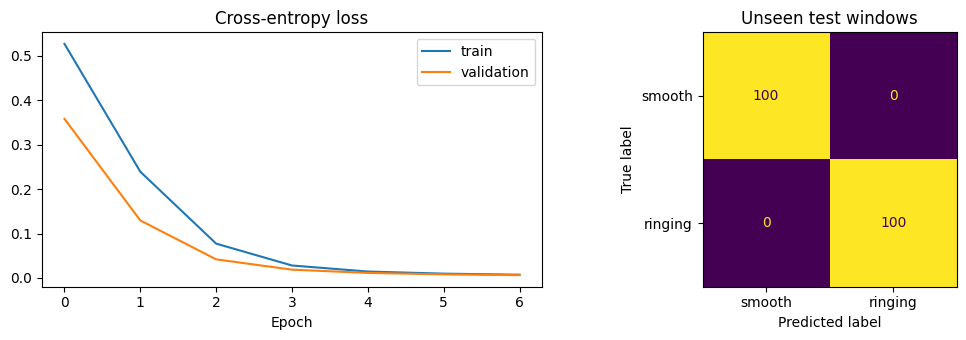

In [8]:
# The network is deliberately small and trains on CPU.
stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)
history_max = cnn_max.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=7, batch_size=64, callbacks=[stop], verbose=0,
)

# Important: fit uses TRAIN / VALIDATION only. TEST is evaluated after training.
prob_max = cnn_max.predict(X_test, verbose=0)
pred_max = np.argmax(prob_max, axis=1)
accuracy_max = accuracy_score(y_test, pred_max)
print(f"CNN + global MAX test accuracy: {accuracy_max:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history_max.history["loss"], label="train")
ax[0].plot(history_max.history["val_loss"], label="validation")
ax[0].set_title("Cross-entropy loss")
ax[0].set_xlabel("Epoch")
ax[0].legend()
ConfusionMatrixDisplay.from_predictions(y_test, pred_max,
    display_labels=["smooth", "ringing"], ax=ax[1], colorbar=False)
ax[1].set_title("Unseen test windows")
plt.tight_layout()
plt.show()

**Interpret:** Why might a convolutional filter outperform the three summary statistics on this task? Does a high validation accuracy guarantee the same performance on measurements from a different machine or a different noise regime?

> **INSTRUCTOR NOTES — After Exercise 5**
>
> **Shape trace:** `[N,128,1] → [N,128,12] → [N,64,12] → [N,64,16] → [N,16] → [N,2]`. The global pooling layer removes the temporal dimension. Receptive features are learned to detect waveform morphology. An engineered-feature baseline may overlook local oscillation shape. Generalization to new sensors is not established by this synthetic test.

## 6. Global maximum versus global average — 15 min

Both globally aggregate over **all time positions**. Maximum pooling emphasizes one strong, short-lived activation; average pooling emphasizes activity sustained throughout the window.

We train a second CNN with the *same filter configuration* but global **average** pooling. To make the comparison fair, we keep the same split, optimizer, training budget and evaluation metric.

**Try it:** Guess which will learn the short localized ringing event faster. Does either pooling operation preserve its exact location?

Model                      Test accuracy
Three engineered statistics  0.645
CNN + global MAX            1.000
CNN + global AVERAGE        0.970
Number of CNN parameters: 1106 1106


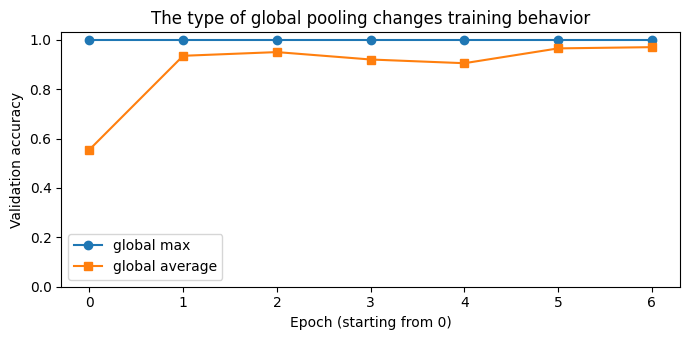

In [9]:
keras.utils.set_random_seed(SEED)
cnn_avg = build_cnn(global_pool="average")
stop_avg = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
history_avg = cnn_avg.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=7, batch_size=64, callbacks=[stop_avg], verbose=0,
)
pred_avg = np.argmax(cnn_avg.predict(X_test, verbose=0), axis=1)
accuracy_avg = accuracy_score(y_test, pred_avg)

print("Model                      Test accuracy")
print(f"Three engineered statistics  {baseline_accuracy:.3f}")
print(f"CNN + global MAX            {accuracy_max:.3f}")
print(f"CNN + global AVERAGE        {accuracy_avg:.3f}")
print("Number of CNN parameters:", cnn_max.count_params(), cnn_avg.count_params())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(history_max.history["val_accuracy"], marker="o", label="global max")
ax.plot(history_avg.history["val_accuracy"], marker="s", label="global average")
ax.set(xlabel="Epoch (starting from 0)", ylabel="Validation accuracy", ylim=(0,1.03),
       title="The type of global pooling changes training behavior")
ax.legend()
plt.tight_layout()
plt.show()

> **INSTRUCTOR NOTES — After Exercise 6**
>
> **Interpretation:** both models see the entire window after global pooling. The maximum emphasizes isolated strong local detections, so it can learn a sparse event faster; the average depends on how widespread an activation is. This is data- and training-dependent, not a universal accuracy ranking. Both pooling operations discard the positions of their input activations.

## 7. What did the filters detect? — 10 min

Instead of looking only at the final class label, visualize **first-layer feature maps**. A strong activation at a time position indicates that some learned local pattern responded there. It does *not* prove that one filter is uniquely interpretable as a named physical fault detector.

**Try it:** Choose another test example or plot another filter index. Do large activations tend to appear near the injected event?

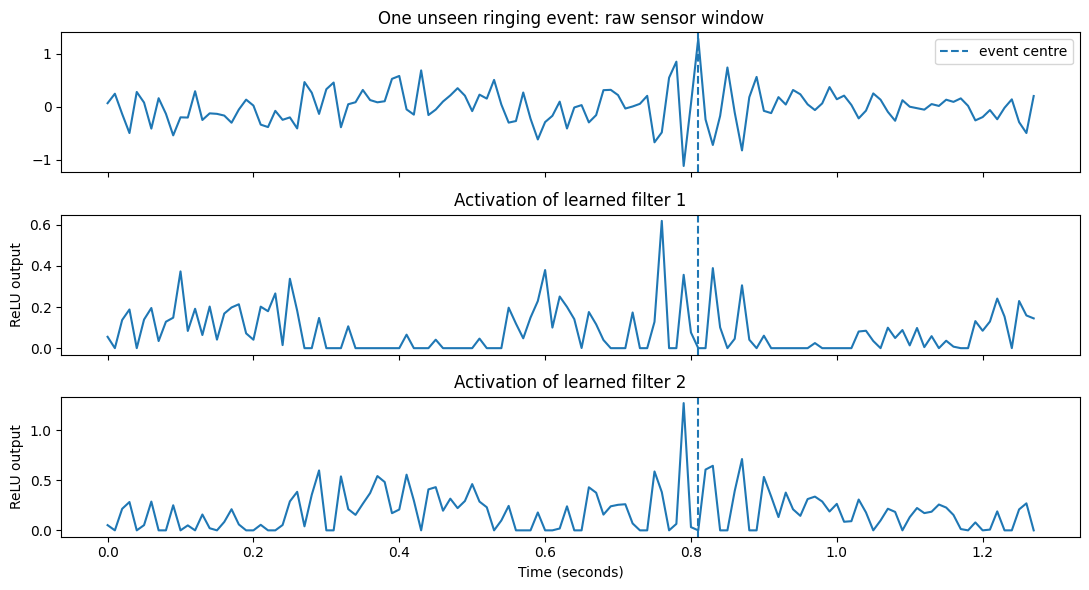

In [10]:
# New model that ends after the FIRST trained Conv1D layer.
first_conv = keras.Model(inputs=cnn_max.inputs, outputs=cnn_max.layers[0].output)
example_id = int(np.flatnonzero(y_test == 1)[0])
example = X_test[example_id:example_id + 1]
feature_maps = np.asarray(first_conv.predict(example, verbose=0))[0]  # [L, 12]

fig, axs = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
times = np.arange(L) / FS
axs[0].plot(times, example[0, :, 0])
axs[0].axvline(centres_test[example_id] / FS, linestyle="--", label="event centre")
axs[0].set_title("One unseen ringing event: raw sensor window")
axs[0].legend(loc="upper right")
for ax, channel in zip(axs[1:], [0, 1]):
    ax.plot(times, feature_maps[:, channel])
    ax.axvline(centres_test[example_id] / FS, linestyle="--")
    ax.set_title(f"Activation of learned filter {channel + 1}")
    ax.set_ylabel("ReLU output")
axs[-1].set_xlabel("Time (seconds)")
plt.tight_layout()
plt.show()

> **INSTRUCTOR NOTES — After Exercise 7**
>
> **Interpretation:** the activations indicate a learned filter's response to local signal regions; some may peak near the labeled event. Individual filters can respond to noise or to several related waveforms. A high response does not by itself prove physical causality or perfect semantic interpretability.

## 8. Downsampling and receptive-field intuition — 10 min

Downsampling reduces the number of temporal positions, but **can lose precise event timing**. At the same time, deeper convolutions can use information covering more of the *original* window, because earlier layers already summarize neighboring positions.

Preview only (slide 98): `Conv1D(K=3) → MaxPool(2) → Conv1D(K=3)`.

**Think:** After the first convolution, each activation can depend on 3 input samples. After pooling and another convolution, can a final activation depend on more than 3 original samples? Why?

**Optional experiment:** Apply max pooling with size 4 to a single-sample pulse. Compare it with average pooling of size 4. Which best retains evidence of a short, strong event, and which gives a more faithful average activity level?

In [11]:
pulse = np.zeros((1, 16, 1), dtype="float32")
pulse[0, 6, 0] = 4.0
pool4_max = keras.layers.MaxPooling1D(pool_size=4, strides=4)(pulse)
pool4_avg = keras.layers.AveragePooling1D(pool_size=4, strides=4)(pulse)
print("Original time positions:", pulse[0, :, 0])
print("After max pooling x4:    ", np.asarray(pool4_max)[0, :, 0])
print("After mean pooling x4:   ", np.asarray(pool4_avg)[0, :, 0])

Original time positions: [0. 0. 0. 0. 0. 0. 4. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
After max pooling x4:     [0. 4. 0. 0.]
After mean pooling x4:    [0. 1. 0. 0.]


> **INSTRUCTOR NOTES — After Exercise 8**
>
> **Expected:** max pooling retains the pulse amplitude `4`; average pooling spreads its contribution into a reduced value `1` in the corresponding pooled region. The later Conv1D uses several pooled positions, each of which summarizes a larger original support. Under these simple settings, one final activation can depend on 8 original samples (3 from first Conv, then pool adds 1, then second Conv adds 2×2). This is only a preview; formal receptive-field computation comes in the next lecture block.

## Wrap-up / submission — 10 min

In a short paragraph or a few annotated plots, answer:

1. How does a Conv1D filter differ from the recurrent hidden-state mechanism from Lecture 4?
2. What do **K**, **stride**, **padding** and **number of filters** control?
3. Why does global pooling help when the *location* of the event does not determine the class?
4. Why may global pooling be unsuitable if the task is to **locate the fault onset time**?
5. Was the CNN better than the three-feature baseline? Is that guaranteed on other datasets?
6. What new question does the receptive-field concept raise for a deeper CNN?

**Extension (optional, not required):** Vary the kernel size from 7 to 3 or 15, keeping all other settings fixed. Use validation results to compare; do not tune on the test set.

---
## Instructor reference: suggested wrap-up answers

1. Conv: same shared local detector at many positions; RNN: shared state update sequentially through time. 2. Kernel: local extent; stride: output spacing; padding: boundaries/output size; filters: output channels. 3. Global pooling enables a location-insensitive window representation. 4. It discards timing, so onset localization needs a time-aligned output. 5. Compare measured performance; no architecture always wins. 6. How much of the original input can influence one deeper activation?

**Teaching notes:** Most students can finish the core exercises in 110–130 minutes. Allow 5 minutes for questions between the pooling and training stages. The example is deliberately simplified and is not a benchmark of production fault-monitoring systems. When comparing max and average global pooling, use the **same validation split** and training budget; results may differ slightly by hardware and package versions. Do not claim that global pooling itself learns long-range temporal *relationships*: it aggregates features across time but loses their positions.